In [4]:
import datetime
import matplotlib.pyplot as plt
from matplotlib import dates
import os
import pandas as pd
import numpy as np
import seaborn as sns
from matplotlib.dates import DateFormatter

plt.style.use('thesis.mplstyle')
sns.set_palette("viridis")
subpalette = sns.color_palette("viridis", 2)


# Constants

In [5]:
xtal_freq = 32680
#xtal_freq = 130000
counter_bits = 29
start_time = datetime.datetime(2026,11,4,10,30,0)
end_time = start_time + datetime.timedelta(days=15)
DATA_ROOT = 'data'
PCBDATA = 'pcb_data.xlsx'

In [17]:
period_after_counter = datetime.timedelta(seconds=(2**counter_bits)/xtal_freq)
on_time = period_after_counter/2

print(period_after_counter)
print(on_time)

lTimes = []
lStatus = []

time = start_time
status = 1
while time < end_time:
    lTimes.append(time)
    lStatus.append(status)

    time += on_time

    lTimes.append(time)
    lStatus.append(status)

    status = not status


4:33:48.118482
2:16:54.059241


# Graph On Time for full time

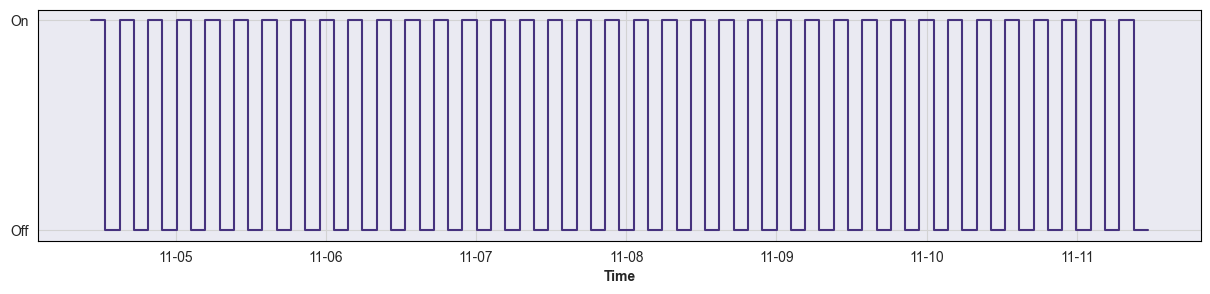

In [12]:
fig, ax = plt.subplots(1,1, figsize=(15,3))
ax.plot(lTimes, lStatus)
ax.set_xlabel('Time')
#fig.tick_params(rotation=45)
ax.set_yticks([0,1],['Off','On'])
plt.gca().xaxis.set_major_formatter(dates.DateFormatter('%m-%d'))


# Graph On Time for a Specific Day

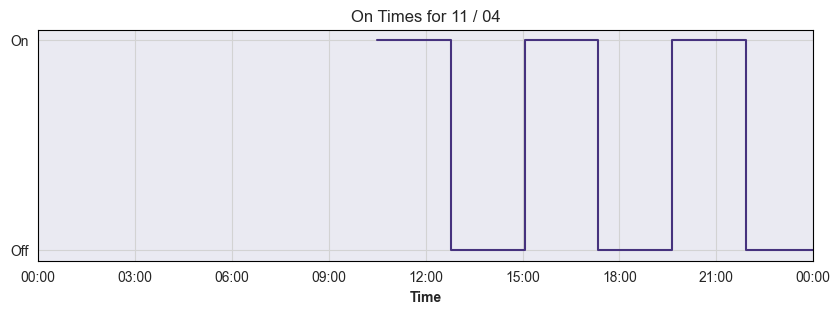

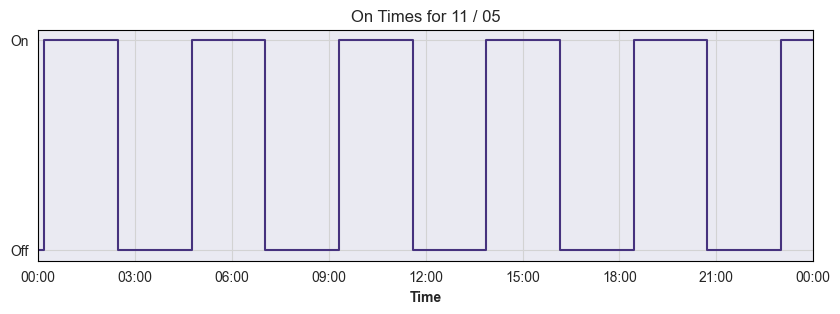

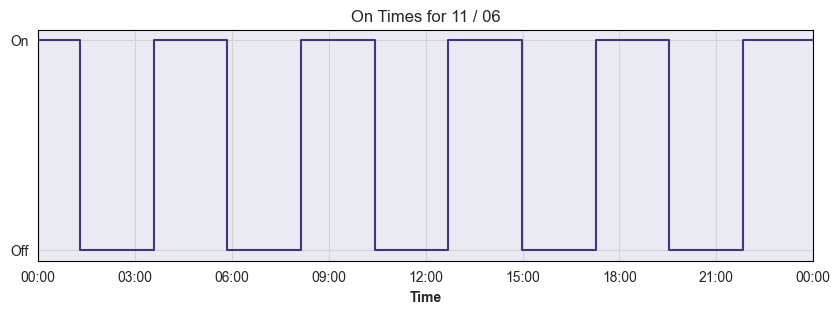

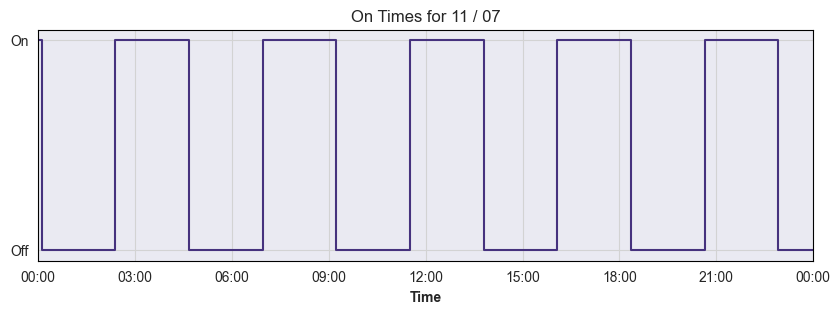

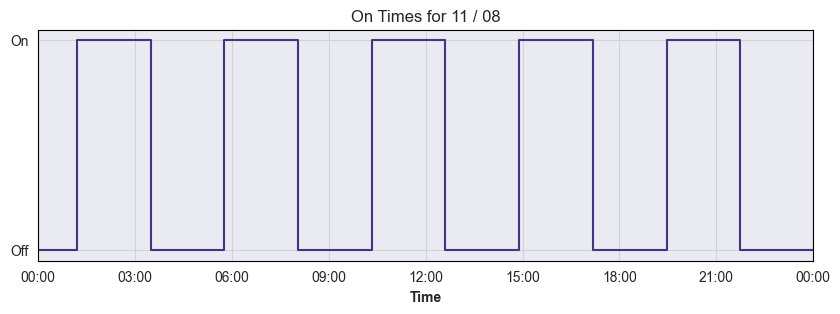

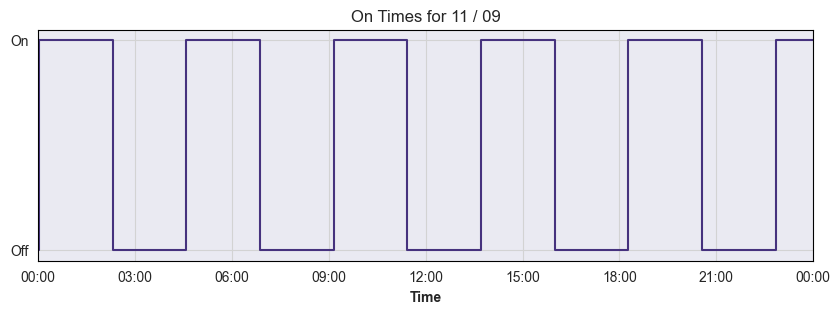

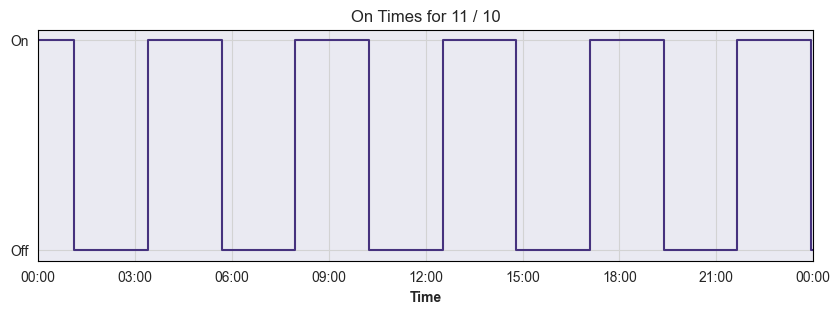

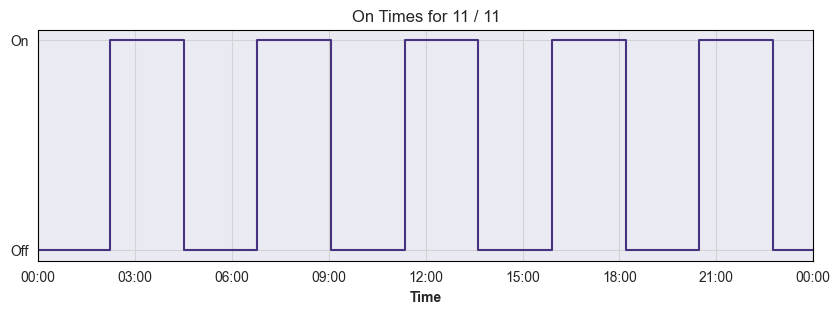

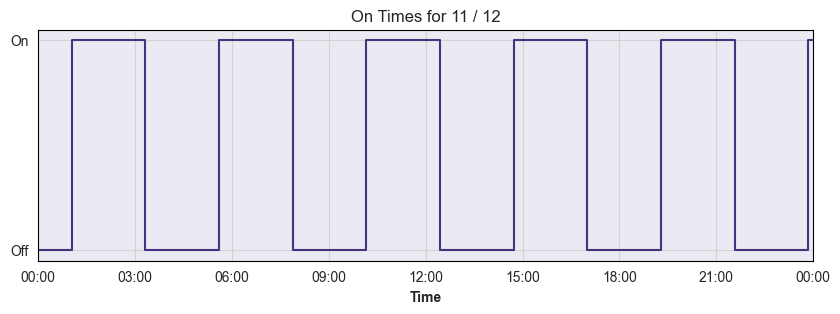

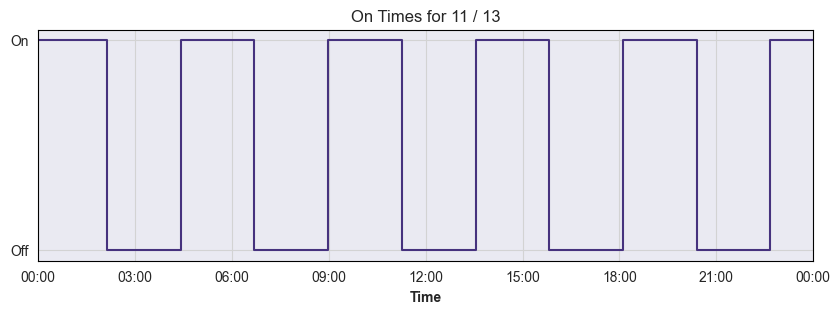

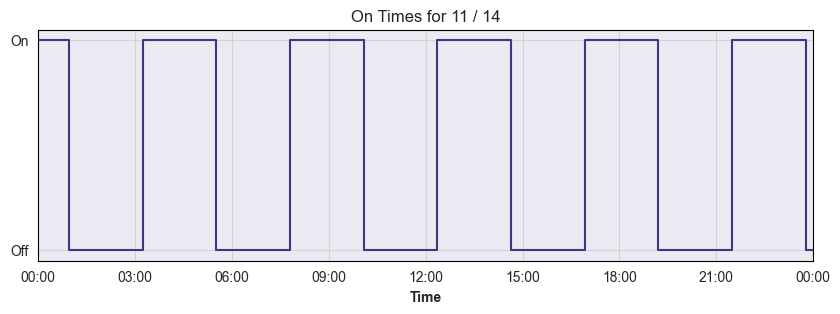

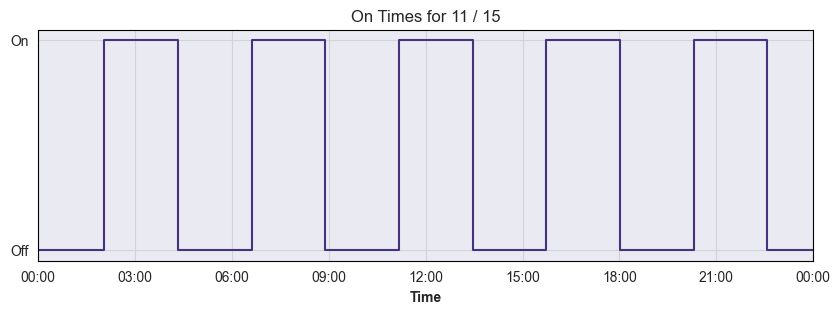

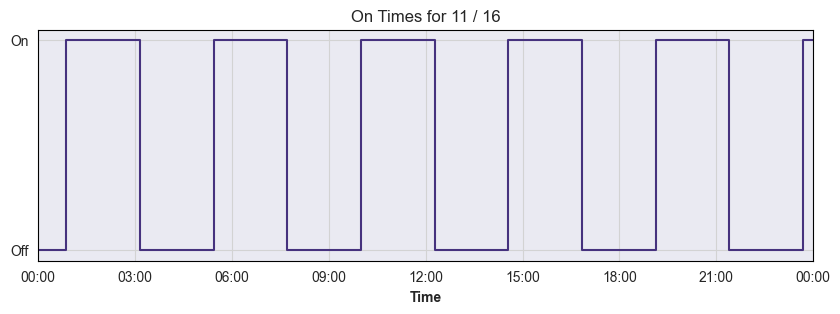

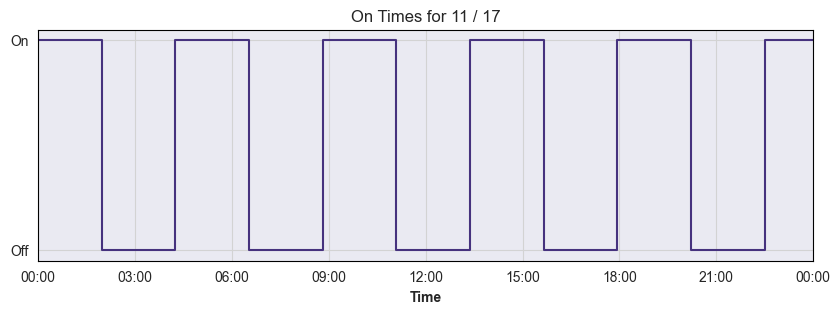

In [18]:
# Enter the date here that you want to graph (year, month, day)
day = datetime.datetime(2026,11,4)

for i in range(1,15):
    fig, ax = plt.subplots(1,1, figsize=(10,3))
    ax.plot(lTimes, lStatus)
    ax.set_xlabel('Time')
    ax.set_xlim(day, day+datetime.timedelta(days=1))
    ax.set_yticks([0,1],['Off','On'])
    plt.gca().xaxis.set_major_formatter(dates.DateFormatter('%H:%M'))
    plt.title('On Times for ' + day.strftime("%m / %d"))
    day = day + datetime.timedelta(days=1)


# Generate Linear Fits for each PCB

In [11]:
DATA_FILEPATH = os.path.join(DATA_ROOT, PCBDATA)
dfPCBs = pd.read_excel(DATA_FILEPATH, sheet_name='LinearFits')
#print(dfPCBs)

# define which data should be used
dfFitFinding = dfPCBs.loc[dfPCBs['Date'] == '2026-10-29']
#print(dfFitFinding)
lPCBsToFit = dfFitFinding['PCB'].unique()
print(lPCBsToFit)

dfFits = pd.DataFrame(columns=['PCB', 'm (V/Hz)', 'b (V)'])
for PCB in lPCBsToFit:
#for PCB in [9]:
    dfFitting = dfFitFinding[dfFitFinding['PCB'] == PCB]
    m, b = np.polyfit(dfFitting['VCO f (Hz)'], dfFitting['Voltage (V)'], 1)
    print(b)
    #plt.plot(dfFitting['VCO f (Hz)'], dfFitting['Voltage (V)'])
    #lV = [1.5, 2, 2.5, 3]
    #lf = [(v-b)/m for v in lV]

    dfFits = pd.concat([dfFits, pd.DataFrame([[PCB, m, b]], columns=dfFits.columns)], ignore_index=True)

print(dfFits)


[1 2 3 4 5 6 7 9]
-35.5430979498864
-36.40499166890924
-36.07365502418144
-34.52198722293242
-36.066630843631785
-35.22926766374413
-35.67128912400056
-35.58777206173378
  PCB m (V/Hz)      b (V)
0   1      0.0 -35.543098
1   2      0.0 -36.404992
2   3      0.0 -36.073655
3   4      0.0 -34.521987
4   5      0.0 -36.066631
5   6      0.0 -35.229268
6   7      0.0 -35.671289
7   9      0.0 -35.587772


In [8]:
dfPlotFitLines = pd.DataFrame(columns=['PCB', 'X', 'Y'])
for pcb in dfFits['PCB'].unique():
    lX = np.linspace(1.8, 3, 10).tolist()
    m = dfFits.loc[dfFits['PCB'] == pcb]['m (V/Hz)'].iloc[0]
    b = dfFits.loc[dfFits['PCB'] == pcb]['b (V)'].iloc[0]
    lY = [(x - b)/m for x in lX]
    dfSubset = pd.DataFrame([lX, lY], index=['X', 'Y']).T
    dfSubset['PCB'] = pcb
    dfPlotFitLines = pd.concat([dfPlotFitLines, dfSubset], ignore_index=True)

print(dfPlotFitLines)

   PCB         X                 Y
0    1       1.8  204135114.942529
1    1  1.933333  204863978.288633
2    1  2.066667  205592841.634738
3    1       2.2  206321704.980843
4    1  2.333333  207050568.326948
..  ..       ...               ...
75   9  2.466667  209051231.884058
76   9       2.6  209783695.652174
77   9  2.733333   210516159.42029
78   9  2.866667  211248623.188406
79   9       3.0  211981086.956522

[80 rows x 3 columns]


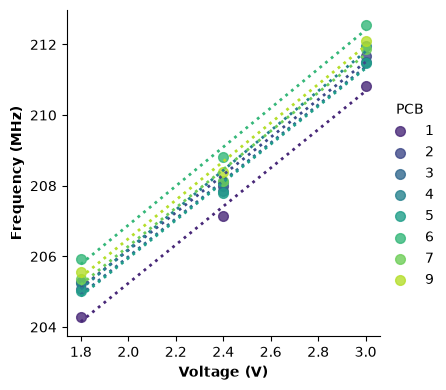

In [9]:
#fig, ax = plt.subplots(1,1, figsize=(4,3))

dfPlot = dfPCBs.loc[dfPCBs['Date'] == '2026-10-29']
dfPlot['Frequency (MHz)'] = dfPlot['VCO f (Hz)']/1e6
sns.lmplot(data=dfPlot, x='Voltage (V)', y='Frequency (MHz)', hue='PCB', ci=None, palette='viridis', height=4, aspect=1, line_kws={'ls': 'dotted', 'linewidth': 2})

plt.savefig('active_comms_linearfits.pdf', format='pdf', transparent=True, bbox_inches='tight')

# Generate Graph of Lab Data

        Date  PCB rev  PCB Number   VBAT supply   VBAT  \
0 2026-06-12      2.0         1.0  Power supply  3.000   
1 2026-06-12      2.0         1.0  Power supply  2.800   
2 2026-06-12      2.0         1.0  Power supply  2.600   
3 2026-06-12      2.0         1.0  Power supply  2.400   
4 2026-06-12      2.0         1.0  Power supply  2.200   
5 2026-06-12      2.0         1.0  Power supply  2.000   
6 2026-06-12      2.0         1.0  Power supply  1.800   
9 2026-06-18      2.0         1.0    Biobattery  1.839   

   Xtal Oscillator Frequency (kHz)  VCO Frequency (MHz)  
0                            32.68              210.650  
1                            32.68              209.425  
2                            32.79              208.200  
3                            32.79              206.925  
4                            32.79              205.650  
5                            32.79              204.575  
6                            32.79              204.250  
9            

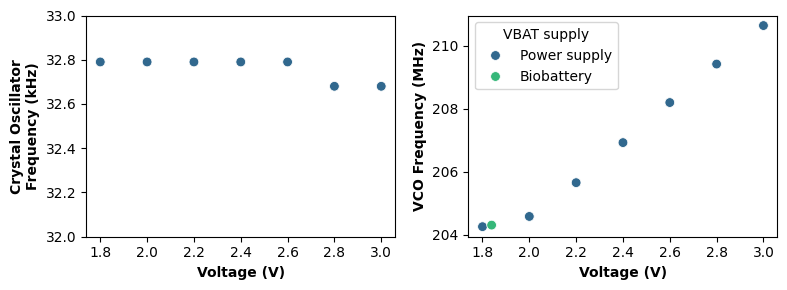

In [27]:
DATA_FILEPATH = os.path.join(DATA_ROOT, PCBDATA)
dfOscillators = pd.read_excel(DATA_FILEPATH, sheet_name='VoltageSweeping')

#print(dfOscillators)
dfPlot = dfOscillators.loc[dfOscillators['VBAT'] > 1.6]
print(dfPlot)

fig, ax = plt.subplots(1,2, figsize=(8,3))

sns.scatterplot(data=dfPlot, x='VBAT', y='Xtal Oscillator Frequency (kHz)', ax=ax[0], hue='VBAT supply', palette=subpalette)
sns.scatterplot(data=dfPlot, x='VBAT', y='VCO Frequency (MHz)', ax=ax[1], hue='VBAT supply', palette=subpalette)

ax[0].set_xlabel('Voltage (V)')
ax[0].set_ylabel('Crystal Oscillator\nFrequency (kHz)')
ax[1].set_xlabel('Voltage (V)')
ax[1].set_ylabel('VCO Frequency (MHz)')
ax[0].legend().remove()
ax[0].set_ylim(32,33)

plt.tight_layout()

plt.savefig('active_comms_pcb_voltage_sweep.pdf', format='pdf', transparent=True, bbox_inches='tight')

# Generate Field Data Graph

In [67]:
DATA_FILEPATH = os.path.join(DATA_ROOT, PCBDATA)
dfFieldData = pd.read_excel(DATA_FILEPATH, sheet_name='FieldData')

dfStartMeasurements = pd.read_excel(DATA_FILEPATH, sheet_name='FieldData_Start')
dfStartMeasurements['Days'] = 0

# generate a column of voltages based on the freq and linear fit  info from that dataframe
lTransponders = dfFieldData['Transponder'].unique()

for transponder in lTransponders:
    m = dfFits.loc[dfFits['PCB'] == transponder]['m (V/Hz)'].iloc[0]
    b = dfFits.loc[dfFits['PCB'] == transponder]['b (V)'].iloc[0]
    start = dfStartMeasurements.loc[dfStartMeasurements['Transponder'] == transponder]['Datetime'].iloc[0]
    print(start)

    dfFieldData.loc[dfFieldData['Transponder'] == transponder, 'Voltage (V)'] = dfFieldData['Peak (MHz)']*m*1e6 + b
    dfFieldData.loc[dfFieldData['Transponder'] == transponder, 'Time Delta'] = dfFieldData['Datetime'] - start


dfFieldData['Days'] = dfFieldData['Time Delta']/ datetime.timedelta(days=1)

print(dfFieldData)

2026-09-07 17:14:00
2026-09-07 17:23:00
             Datetime  Transponder  Peak (MHz)  Voltage (V)      Time Delta  \
0 2026-09-08 15:30:00            6     208.045     2.210055 0 days 22:16:00   
1 2026-09-08 15:30:00            5     207.450     2.267955 0 days 22:07:00   
2 2026-09-09 15:30:00            6     206.910     2.007308 1 days 22:16:00   
3 2026-09-09 15:30:00            5     205.540     1.913567 1 days 22:07:00   
4 2026-09-10 11:30:00            6     205.370     1.732215 2 days 18:16:00   
5 2026-09-10 11:30:00            5     205.300     1.869037 2 days 18:07:00   
6 2026-09-11 16:30:00            5     204.580     1.735446 3 days 23:07:00   
7 2026-09-12 07:30:00            6     205.080     1.680411 4 days 14:16:00   
8 2026-09-12 07:30:00            5     203.760     1.583300 4 days 14:07:00   
9 2026-09-13 19:00:00            6     204.940     1.655403 6 days 01:46:00   

       Days  
0  0.927778  
1  0.921528  
2  1.927778  
3  1.921528  
4  2.761111  
5  2.7

              Datetime  Transponder  Peak (MHz)  Voltage (V)      Time Delta  \
0  2026-09-08 15:30:00            6     208.045     2.210055 0 days 22:16:00   
1  2026-09-08 15:30:00            5     207.450     2.267955 0 days 22:07:00   
2  2026-09-09 15:30:00            6     206.910     2.007308 1 days 22:16:00   
3  2026-09-09 15:30:00            5     205.540     1.913567 1 days 22:07:00   
4  2026-09-10 11:30:00            6     205.370     1.732215 2 days 18:16:00   
5  2026-09-10 11:30:00            5     205.300     1.869037 2 days 18:07:00   
6  2026-09-11 16:30:00            5     204.580     1.735446 3 days 23:07:00   
7  2026-09-12 07:30:00            6     205.080     1.680411 4 days 14:16:00   
8  2026-09-12 07:30:00            5     203.760     1.583300 4 days 14:07:00   
9  2026-09-13 19:00:00            6     204.940     1.655403 6 days 01:46:00   
10 2026-09-07 17:23:00            5         NaN     2.710000             NaT   
11 2026-09-07 17:14:00            6     

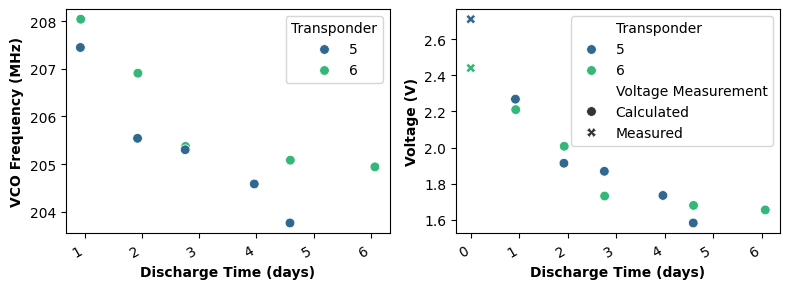

In [71]:
fig, ax = plt.subplots(1,2, figsize=(8,3))

dfFieldData['Voltage'] = 'Calculated'
dfStartMeasurements['Voltage'] = 'Measured'
dfPlot = pd.concat([dfFieldData, dfStartMeasurements], ignore_index=True)
print(dfPlot)

sns.scatterplot(data=dfPlot, x='Days', y='Peak (MHz)', ax=ax[0], hue='Transponder', palette=subpalette)
sns.scatterplot(data=dfPlot, x='Days', y='Voltage (V)', ax=ax[1], hue='Transponder', palette=subpalette, style='Voltage Measurement')

#  Plot Measured Voltage in Field
#ax[1].scatter(0, 2.71, marker='x', color=subpalette[0])
#ax[1].scatter(0, 2.44, marker='x', color=subpalette[1])

ax[0].set_xlabel('Discharge Time (days)')
ax[0].set_ylabel('VCO Frequency (MHz)')
ax[1].set_xlabel('Discharge Time (days)')
ax[1].set_ylabel('Voltage (V)')

#plt.gca().xaxis.set_major_formatter(dates.DateFormatter('%d'))
plt.gcf().autofmt_xdate()
plt.tight_layout()

plt.savefig('active_comms_field_data.pdf', format='pdf', transparent=True, bbox_inches='tight')

dfPlot.to_csv('active_comms_field_data.csv', index=False)
